In [3]:
# ==============================================================================
# Import modules
# ==============================================================================

import matplotlib.pyplot as plt
import numpy as np
from sklearn import datasets
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# ==============================================================================
# Load data and select features 
# Split into training and test data
# ==============================================================================
data = datasets.load_iris()
X = data.data
y = data.target
print(data.feature_names)

# Split data into training and test data (70% training, 30% test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=1, stratify=y)

# ==============================================================================
# Scale features using StandardScaler class in scikit-learn
# ==============================================================================

# Initialise standard scaler and compute mean and STD from the training data
sc = StandardScaler()
sc.fit(X_train)

# Transform (standardise) both X_train and X_test with mean and stddev from
# the training data
X_train_sc = sc.transform(X_train)
X_test_sc = sc.transform(X_test)

print("Mean of X_train_sc:", np.mean(X_train_sc, axis=0))
print("Stddev of X_train_sc:", np.std(X_train_sc, axis=0))

# df = pd.DataFrame(X_test_sc, columns=data.feature_names)
# df["target"] = y_test
# fig, ax = plt.subplots(1, 1, figsize=(20,4))
# sns.violinplot(df, ax=ax)

['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
Mean of X_train_sc: [ 1.50144447e-15 -4.70523091e-17  5.70971841e-17  7.19001578e-17]
Stddev of X_train_sc: [1. 1. 1. 1.]


Accuracy test: 0.76
Accuracy train: 0.84
Accuracy test: 0.76
Accuracy train: 0.85
Accuracy test: 0.78
Accuracy train: 0.84
Accuracy test: 0.80
Accuracy train: 0.85
Accuracy test: 0.80
Accuracy train: 0.87
Accuracy test: 0.84
Accuracy train: 0.91
Accuracy test: 0.98
Accuracy train: 0.94
Accuracy test: 0.98
Accuracy train: 0.94
Accuracy test: 0.98
Accuracy train: 0.94
Accuracy test: 0.98
Accuracy train: 0.95


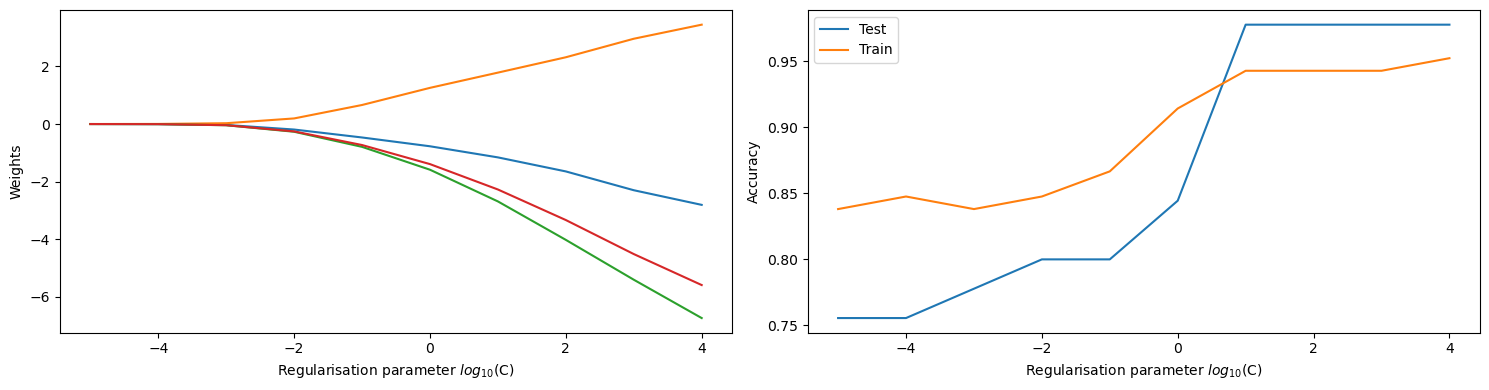

In [4]:
# ==============================================================================
# Train Logistic Regression model with different regularisation parameters
# ==============================================================================

c_range = np.arange(-5, 5, 1.0)
accuracy = np.zeros(shape=(2, len(c_range)))
weights = []

for index, c in enumerate(c_range):
    clf = LogisticRegression(
        max_iter=100, penalty="l2", solver="liblinear", multi_class="auto", random_state=1, C=10.0**c
    )
    clf.fit(X_train_sc, y_train)
    test_score = clf.score(X_test_sc, y_test)
    train_score = clf.score(X_train_sc, y_train)
    accuracy[0, index] = test_score
    accuracy[1, index] = train_score
    print(f"Accuracy test: {test_score:.2f}")
    print(f"Accuracy train: {train_score:.2f}")

    weights.append(clf.coef_[0])


fig, ax = plt.subplots(1, 2, figsize=(15, 4))

ax[0].plot(c_range, weights)
ax[0].set_xlabel("Regularisation parameter $log_{10}$(C)")
ax[0].set_ylabel("Weights")


ax[1].plot(c_range, accuracy[0], label="Test")
ax[1].plot(c_range, accuracy[1], label="Train")
ax[1].set_xlabel("Regularisation parameter $log_{10}$(C)")
ax[1].set_ylabel("Accuracy")
ax[1].legend()


fig.tight_layout()
plt.show()